# Store Sales - Time Series Forecasting

Kaggle competition: forecast daily sales for 54 stores x 33 product families (1,782 series), 16 days ahead (2017-08-16 to 2017-08-31). Metric: RMSLE.

Steps: load data, EDA, validation split, baselines, LightGBM (global + per family), submission.

In [1]:
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

DATA = Path("store-sales-time-series-forecasting")
OUT = Path("submissions")
OUT.mkdir(exist_ok=True)

HORIZON = 16
KEYS = ["store_nbr", "family"]

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUE_LIGHT, BLUE_DARK = "#9ec5f4", "#1c5cab"
plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8981",
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
    "lines.linewidth": 2,
})

## 1. Load the data

In [2]:
train = pd.read_csv(DATA / "train.csv", parse_dates=["date"])
test = pd.read_csv(DATA / "test.csv", parse_dates=["date"])
stores = pd.read_csv(DATA / "stores.csv")
oil = pd.read_csv(DATA / "oil.csv", parse_dates=["date"])
holidays = pd.read_csv(DATA / "holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(DATA / "transactions.csv", parse_dates=["date"])

for name, df in [("train", train), ("test", test), ("stores", stores), ("oil", oil),
                 ("holidays", holidays), ("transactions", transactions)]:
    print(f"{name:13s} {str(df.shape):15s} {df['date'].min().date() if 'date' in df else ''} → "
          f"{df['date'].max().date() if 'date' in df else ''}")
train.head()

train         (3000888, 6)    2013-01-01 → 2017-08-15
test          (28512, 5)      2017-08-16 → 2017-08-31
stores        (54, 5)          → 
oil           (1218, 2)       2013-01-01 → 2017-08-31
holidays      (350, 6)        2012-03-02 → 2017-12-26
transactions  (83488, 3)      2013-01-01 → 2017-08-15


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [3]:
all_days = pd.date_range(train["date"].min(), train["date"].max())
print("Missing dates in train:", list(all_days.difference(train["date"].unique()).date))
print(f"Share of zero sales: {(train['sales'] == 0).mean():.1%}")
series_total = train.groupby(KEYS)["sales"].sum()
print("Series that never sell:", (series_total == 0).sum())
first_sale = train[train["sales"] > 0].groupby("store_nbr")["date"].min()
print("Stores that opened late:\n", first_sale[first_sale > "2013-01-31"].sort_values())

Missing dates in train: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
Share of zero sales: 31.3%


Series that never sell: 53


Stores that opened late:
 store_nbr
36   2013-05-09
53   2014-05-29
20   2015-02-13
29   2015-03-20
21   2015-07-24
42   2015-08-21
22   2015-10-09
52   2017-04-20
Name: date, dtype: datetime64[us]


## 2. EDA

### 2.1 Trend
Total sales over all stores + 28-day moving average.

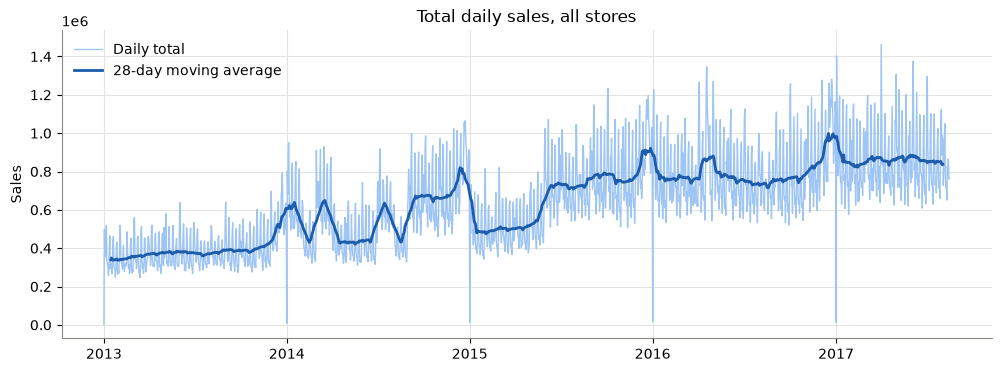

In [4]:
daily = train.groupby("date")["sales"].sum()

fig, ax = plt.subplots()
ax.plot(daily.index, daily, color=BLUE_LIGHT, linewidth=1, label="Daily total")
ax.plot(daily.index, daily.rolling(28, center=True).mean(), color=BLUE_DARK,
        label="28-day moving average")
ax.set_title("Total daily sales, all stores")
ax.set_ylabel("Sales")
ax.legend(frameon=False)
plt.show()

Sales go up until 2015, then flatten. Drops to ~0 are January 1st (stores closed), Christmas is missing from the data. April 2016 = earthquake.

### 2.2 Seasonality

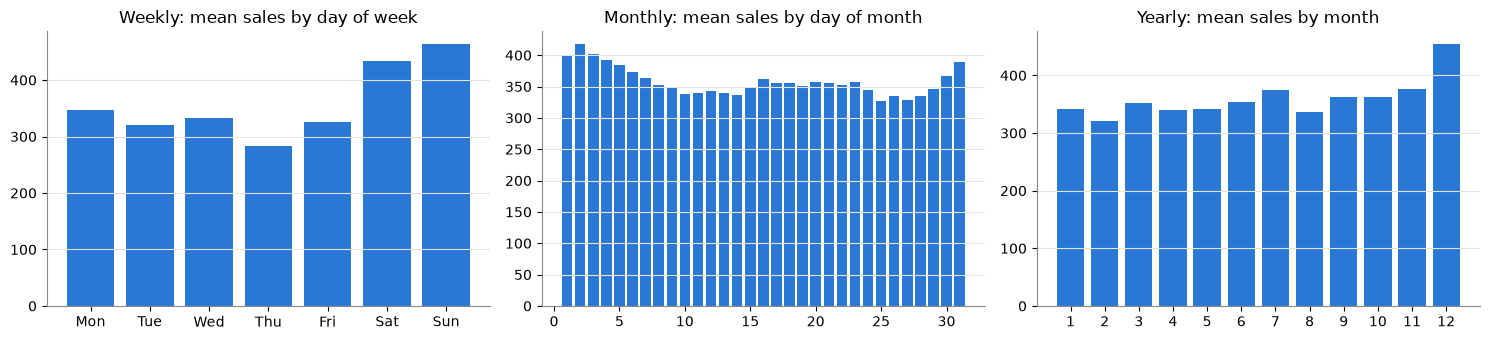

In [5]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow = train.groupby(train["date"].dt.day_of_week)["sales"].mean()
by_dom = train.groupby(train["date"].dt.day)["sales"].mean()
by_month = train.groupby(train["date"].dt.month)["sales"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].bar(dow_names, by_dow.values, color=BLUE)
axes[0].set_title("Weekly: mean sales by day of week")
axes[1].bar(by_dom.index, by_dom.values, color=BLUE)
axes[1].set_title("Monthly: mean sales by day of month")
axes[2].bar(by_month.index, by_month.values, color=BLUE)
axes[2].set_title("Yearly: mean sales by month")
axes[2].set_xticks(range(1, 13))
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

- Weekly pattern is the strongest, weekends ~30% higher than Thursday
- Bumps around the 15th and start of the month (paydays are the 15th and last day of the month)
- December peak

### 2.3 Decomposition (last year, weekly period)

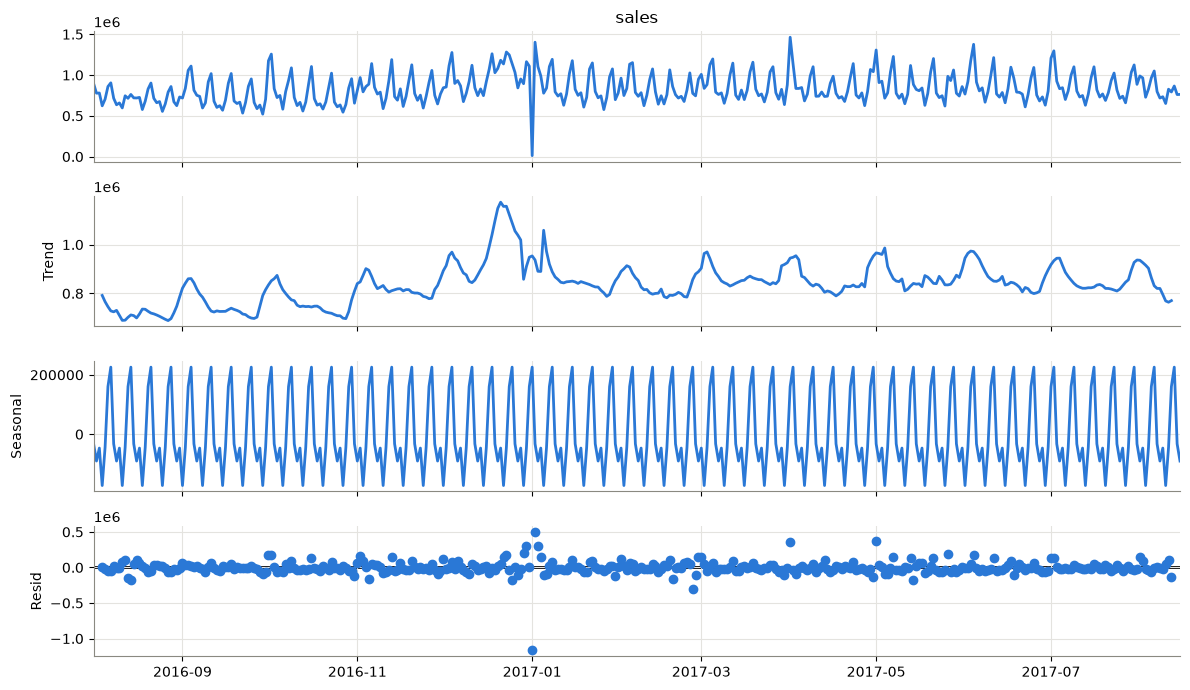

In [6]:
recent = daily.loc["2016-08-01":].asfreq("D").interpolate()
decomp = seasonal_decompose(recent, model="additive", period=7)
fig = decomp.plot()
fig.set_size_inches(12, 7)
plt.tight_layout()
plt.show()

### 2.4 ACF / PACF
Spikes at lags 7, 14, 21 -> weekly pattern.

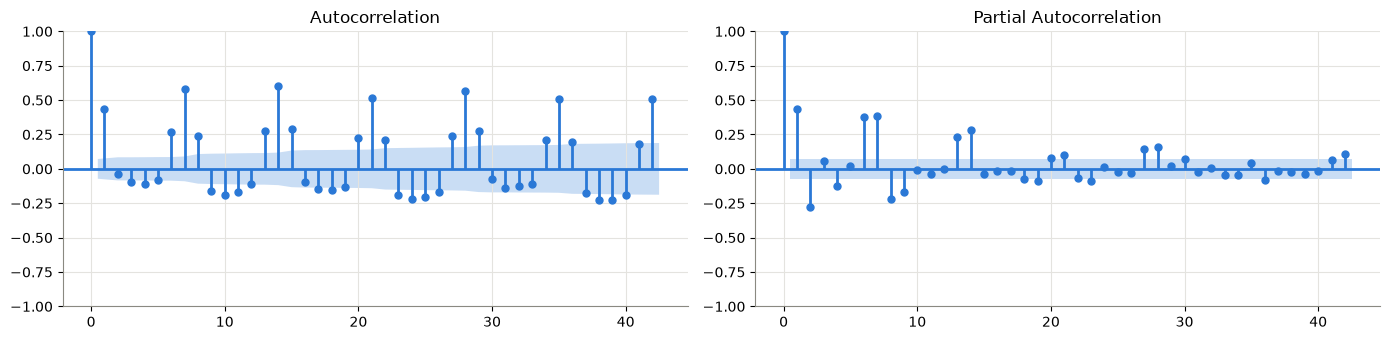

In [7]:
y_recent = daily.loc["2015-08-01":].asfreq("D").interpolate()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(y_recent, lags=42, ax=axes[0], color=BLUE)
plot_pacf(y_recent, lags=42, ax=axes[1], color=BLUE, method="ywm")
plt.tight_layout()
plt.show()

### 2.5 Stationarity (ADF test)

In [8]:
def adf_report(series, name):
    stat, pvalue, *_ = adfuller(series.dropna(), result_object=False)
    verdict = "stationary" if pvalue < 0.05 else "NOT stationary"
    print(f"{name:35s} ADF={stat:7.2f}  p-value={pvalue:.4f}  → {verdict}")

y_full = daily.asfreq("D").interpolate()
adf_report(y_full, "Raw daily total")
adf_report(y_full.diff(), "1st difference (y_t − y_{t−1})")
adf_report(y_full.diff(7), "Weekly difference (y_t − y_{t−7})")

Raw daily total                     ADF=  -2.62  p-value=0.0887  → NOT stationary
1st difference (y_t − y_{t−1})      ADF= -11.36  p-value=0.0000  → stationary
Weekly difference (y_t − y_{t−7})   ADF= -11.14  p-value=0.0000  → stationary


### 2.6 Oil price

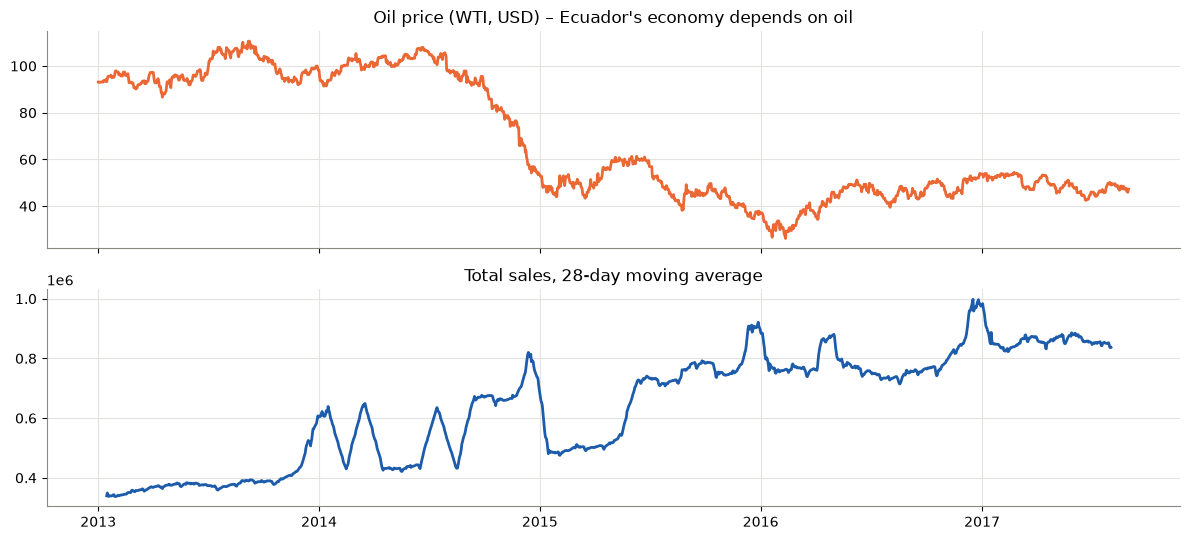

Monthly correlation oil vs. sales: -0.79


In [9]:
oil_daily = oil.set_index("date")["dcoilwtico"].reindex(
    pd.date_range(oil["date"].min(), oil["date"].max())).ffill().bfill()

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(oil_daily.index, oil_daily, color=ORANGE)
axes[0].set_title("Oil price (WTI, USD) – Ecuador's economy depends on oil")
axes[1].plot(daily.index, daily.rolling(28, center=True).mean(), color=BLUE_DARK)
axes[1].set_title("Total sales, 28-day moving average")
plt.tight_layout()
plt.show()

monthly = pd.DataFrame({"oil": oil_daily.resample("MS").mean(),
                        "sales": daily.resample("MS").mean()}).dropna()
print(f"Monthly correlation oil vs. sales: {monthly.corr().iloc[0, 1]:.2f}")

### 2.7 Promotions and holidays

In [10]:
promo = train.assign(promo=np.where(train["onpromotion"] > 0, "on promotion", "no promotion"))
promo_table = (promo.groupby(["family", "promo"])["sales"].mean().unstack()
               .assign(ratio=lambda d: d["on promotion"] / d["no promotion"])
               .sort_values("ratio", ascending=False))
print("Mean sales with vs. without promotion (top families):")
promo_table.head(10).round(1)

Mean sales with vs. without promotion (top families):


promo,no promotion,on promotion,ratio
family,,,
SCHOOL AND OFFICE SUPPLIES,1.0,44.5,43.6
BABY CARE,0.1,1.7,15.1
PET SUPPLIES,3.5,15.8,4.5
HOME AND KITCHEN II,10.3,41.2,4.0
PRODUCE,792.1,2438.2,3.1
HOME APPLIANCES,0.5,1.4,3.1
LAWN AND GARDEN,5.5,16.8,3.0
HOME CARE,102.0,309.4,3.0
PLAYERS AND ELECTRONICS,6.1,17.4,2.9


In [11]:
hol_nat = holidays[(holidays["locale"] == "National") & (~holidays["transferred"])]
day_type = hol_nat.drop_duplicates("date").set_index("date")["type"]
daily_df = daily.to_frame("sales").assign(
    day_type=lambda d: day_type.reindex(d.index).fillna("Normal day"))
# relative to the yearly mean
daily_df["vs_year_mean"] = daily_df["sales"] / daily_df.groupby(daily_df.index.year)["sales"].transform("mean")
daily_df[daily_df.index.strftime("%m-%d") != "01-01"].groupby("day_type")["vs_year_mean"].agg(["mean", "count"]).round(2)

,mean,count
day_type,,
Additional,1.53,28
Bridge,1.20,3
Event,1.04,53
Holiday,1.09,36
Normal day,0.99,1547
Transfer,1.15,7
Work Day,1.19,5


Promotions and holidays both have a clear effect -> used as features.

## 3. Validation split
Last 16 days of train as validation (same length as the test horizon).

In [12]:
VALID_START = train["date"].max() - pd.Timedelta(days=HORIZON - 1)
tr_part = train[train["date"] < VALID_START]
va_part = train[train["date"] >= VALID_START]
print(f"Train: {tr_part['date'].min().date()} → {tr_part['date'].max().date()}")
print(f"Valid: {va_part['date'].min().date()} → {va_part['date'].max().date()}  ({va_part['date'].nunique()} days)")


def rmsle(y_true, y_pred):
    y_pred = np.clip(y_pred, 0, None)
    return float(np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2)))

Train: 2013-01-01 → 2017-07-30
Valid: 2017-07-31 → 2017-08-15  (16 days)


## 4. Baselines
- naive: last observed day
- seasonal_naive: same day last week
- mean_14: mean of the last 14 days
- dow_mean_4w: mean of the same weekday over the last 4 weeks

In [13]:
def forecast_baseline(history, target, method):
    last = history["date"].max()
    h = history[history["date"] > last - pd.Timedelta(days=28)]
    h = h.assign(dow=h["date"].dt.day_of_week)
    t = target.assign(dow=target["date"].dt.day_of_week)

    if method == "naive":
        ref, on = h.loc[h["date"] == last, KEYS + ["sales"]], KEYS
    elif method == "seasonal_naive":
        ref, on = h.loc[h["date"] > last - pd.Timedelta(days=7), KEYS + ["dow", "sales"]], KEYS + ["dow"]
    elif method == "mean_14":
        ref = h[h["date"] > last - pd.Timedelta(days=14)].groupby(KEYS, as_index=False)["sales"].mean()
        on = KEYS
    elif method == "dow_mean_4w":
        ref, on = h.groupby(KEYS + ["dow"], as_index=False)["sales"].mean(), KEYS + ["dow"]
    else:
        raise ValueError(method)

    out = t[on].merge(ref.rename(columns={"sales": "pred"}), on=on, how="left")
    return out["pred"].fillna(0).to_numpy()


results = {}
valid_preds = {}
for method in ["naive", "seasonal_naive", "mean_14", "dow_mean_4w"]:
    valid_preds[method] = forecast_baseline(tr_part, va_part, method)
    results[method] = rmsle(va_part["sales"].to_numpy(), valid_preds[method])

pd.Series(results, name="RMSLE (valid)").sort_values().round(4).to_frame()

,RMSLE (valid)
mean_14,0.5191
dow_mean_4w,0.5311
seasonal_naive,0.6170
naive,0.6595


## 5. LightGBM

Target is `log1p(sales)`, so RMSE on it = RMSLE.
All sales features use lags >= 16 days (the horizon), so one model can predict the 16 days directly without leakage.

### 5.1 Full date x store x family grid

In [14]:
all_dates = pd.date_range(train["date"].min(), test["date"].max())
grid = pd.MultiIndex.from_product(
    [sorted(train["store_nbr"].unique()), sorted(train["family"].unique()), all_dates],
    names=["store_nbr", "family", "date"]).to_frame(index=False)

full = grid.merge(pd.concat([train, test], ignore_index=True), on=KEYS + ["date"], how="left")
is_train_day = full["date"] <= train["date"].max()
# Christmas missing -> stores closed
full.loc[is_train_day, "sales"] = full.loc[is_train_day, "sales"].fillna(0)
full["onpromotion"] = full["onpromotion"].fillna(0)
full = full.sort_values(KEYS + ["date"], ignore_index=True)
full["y"] = np.log1p(full["sales"])
print(full.shape)

(3036528, 7)


### 5.2 Lags and rolling features

In [15]:
# wide format (date x series) to shift / roll everything at once
wide = full.pivot(index="date", columns=KEYS, values="y")
to_long = lambda w: w.to_numpy().T.ravel().astype(np.float32)
assert np.allclose(np.nan_to_num(to_long(wide), nan=-1), np.nan_to_num(full["y"].to_numpy(), nan=-1))

for lag in [16, 17, 18, 19, 20, 21, 28, 35, 42, 364]:
    full[f"lag_{lag}"] = to_long(wide.shift(lag))

base = wide.shift(HORIZON)
for w in [7, 14, 28, 56, 112]:
    full[f"roll_mean_{w}"] = to_long(base.rolling(w, min_periods=1).mean())
full["roll_std_28"] = to_long(base.rolling(28, min_periods=2).std())
full["zero_days_28"] = to_long((base == 0).rolling(28, min_periods=1).sum())
full["dow_mean_4w"] = to_long((wide.shift(21) + wide.shift(28) + wide.shift(35) + wide.shift(42)) / 4)

promo_wide = full.pivot(index="date", columns=KEYS, values="onpromotion")
full["promo_roll_mean_14"] = to_long(promo_wide.rolling(14, min_periods=1).mean())

### 5.3 Calendar, store, oil, holidays

In [16]:
d = full["date"]
full["dow"] = d.dt.day_of_week
full["day"] = d.dt.day
full["month"] = d.dt.month
full["year"] = d.dt.year
full["dayofyear"] = d.dt.day_of_year
full["is_payday"] = ((d.dt.day == 15) | d.dt.is_month_end).astype(int)

full = full.merge(stores, on="store_nbr", how="left")
full["oil"] = oil_daily.reindex(full["date"]).bfill().to_numpy()
full["oil_roll_28"] = oil_daily.rolling(28, min_periods=1).mean().reindex(full["date"]).bfill().to_numpy()

hol = holidays[~holidays["transferred"]]
day_off = hol["type"].isin(["Holiday", "Transfer", "Additional", "Bridge"])
national = list(set(hol.loc[day_off & (hol["locale"] == "National"), "date"]))
events = list(set(hol.loc[hol["type"] == "Event", "date"]))
regional = (hol.loc[day_off & (hol["locale"] == "Regional"), ["date", "locale_name"]]
            .rename(columns={"locale_name": "state"}).drop_duplicates().assign(regional_holiday=1))
local = (hol.loc[day_off & (hol["locale"] == "Local"), ["date", "locale_name"]]
         .rename(columns={"locale_name": "city"}).drop_duplicates().assign(local_holiday=1))

full["national_holiday"] = full["date"].isin(national).astype(int)
full["event"] = full["date"].isin(events).astype(int)
full = full.merge(regional, on=["date", "state"], how="left").merge(local, on=["date", "city"], how="left")
full[["regional_holiday", "local_holiday"]] = full[["regional_holiday", "local_holiday"]].fillna(0)

### 5.4 More features
Store and family level trends, EWM, same weekday over 8 weeks, promo lag/lead, days to/from holidays.

In [17]:
sales_wide = np.expm1(wide)
for level, name in [("store_nbr", "store"), ("family", "fam")]:
    agg = np.log1p(sales_wide.T.groupby(level=level).sum().T).shift(HORIZON)
    for w in (7, 28):
        rolled = agg.rolling(w, min_periods=1).mean()
        rolled.columns = rolled.columns.astype(str)
        long = rolled.reset_index().melt(id_vars="date", var_name=level, value_name=f"{name}_roll_{w}")
        if level == "store_nbr":
            long[level] = long[level].astype(full[level].dtype)
        full = full.merge(long, on=[level, "date"], how="left")

for alpha in (0.1, 0.3):
    full[f"ewm_{alpha}"] = to_long(base.ewm(alpha=alpha).mean())
full["dow_mean_8w"] = to_long(sum(wide.shift(7 * k) for k in range(3, 11)) / 8)

full["promo_lag_1"] = to_long(promo_wide.shift(1))
full["promo_lead_1"] = to_long(promo_wide.shift(-1))
full["promo_ratio_14"] = full["onpromotion"] / (full["promo_roll_mean_14"] + 1)

nat = pd.DatetimeIndex(sorted(national))
dates = pd.DatetimeIndex(sorted(full["date"].unique()))
nxt = nat[np.searchsorted(nat, dates, side="left").clip(max=len(nat) - 1)]
prv = nat[(np.searchsorted(nat, dates, side="right") - 1).clip(min=0)]
hol_dist = pd.DataFrame({"date": dates, "days_to_holiday": np.clip((nxt - dates).days, 0, 30),
                         "days_from_holiday": np.clip((dates - prv).days, 0, 30)})
full = full.merge(hol_dist, on="date", how="left")

In [18]:
CATEGORICAL = ["store_nbr", "family", "city", "state", "type", "cluster"]
for col in CATEGORICAL:
    full[col] = full[col].astype("category")

FEATURES = [c for c in full.columns if c not in ["id", "date", "sales", "y"]]
print(len(FEATURES), "features:", FEATURES)

50 features: ['store_nbr', 'family', 'onpromotion', 'lag_16', 'lag_17', 'lag_18', 'lag_19', 'lag_20', 'lag_21', 'lag_28', 'lag_35', 'lag_42', 'lag_364', 'roll_mean_7', 'roll_mean_14', 'roll_mean_28', 'roll_mean_56', 'roll_mean_112', 'roll_std_28', 'zero_days_28', 'dow_mean_4w', 'promo_roll_mean_14', 'dow', 'day', 'month', 'year', 'dayofyear', 'is_payday', 'city', 'state', 'type', 'cluster', 'oil', 'oil_roll_28', 'national_holiday', 'event', 'regional_holiday', 'local_holiday', 'store_roll_7', 'store_roll_28', 'fam_roll_7', 'fam_roll_28', 'ewm_0.1', 'ewm_0.3', 'dow_mean_8w', 'promo_lag_1', 'promo_lead_1', 'promo_ratio_14', 'days_to_holiday', 'days_from_holiday']


### 5.5 Global model vs one model per family
Training from 2015, earthquake month removed. Final prediction = average of both models.

In [19]:
TRAIN_FROM = pd.Timestamp("2015-01-01")
LAST_TRAIN = train["date"].max()
earthquake = full["date"].between("2016-04-16", "2016-05-15")

GLOBAL_PARAMS = dict(
    objective="regression", learning_rate=0.05, num_leaves=255, min_data_in_leaf=100,
    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
    verbose=-1, seed=42,
)
FAMILY_PARAMS = dict(GLOBAL_PARAMS, num_leaves=63, min_data_in_leaf=50)
FAMILY_FEATURES = [f for f in FEATURES if f != "family"]
FAMILY_CATEGORICAL = [c for c in CATEGORICAL if c != "family"]


def fit_lgb(fit, features, cats, params, val=None, rounds=3000):
    dtrain = lgb.Dataset(fit[features], fit["y"], categorical_feature=cats)
    if val is None:
        return lgb.train(params, dtrain, num_boost_round=rounds)
    dvalid = lgb.Dataset(val[features], val["y"], reference=dtrain)
    return lgb.train(params, dtrain, num_boost_round=rounds, valid_sets=[dvalid],
                     callbacks=[lgb.early_stopping(100, verbose=False)])


def predict_global(fit, val):
    model = fit_lgb(fit, FEATURES, CATEGORICAL, GLOBAL_PARAMS, val)
    return model.predict(val[FEATURES], num_iteration=model.best_iteration), model.best_iteration, model


def predict_per_family(fit, val):
    pred, iters = np.zeros(len(val)), {}
    fit_groups = fit.groupby("family", observed=True)
    for fam, vpart in val.groupby("family", observed=True):
        model = fit_lgb(fit_groups.get_group(fam), FAMILY_FEATURES, FAMILY_CATEGORICAL, FAMILY_PARAMS, vpart)
        pred[val.index.get_indexer(vpart.index)] = model.predict(vpart[FAMILY_FEATURES],
                                                                 num_iteration=model.best_iteration)
        iters[fam] = model.best_iteration
    return pred, iters


def postprocess(frame, pred_log):
    # series with no sales in the last 28 days -> 0
    pred = np.clip(np.expm1(pred_log), 0, None)
    return np.where(frame["zero_days_28"].to_numpy() >= 28, 0, pred)

### 5.6 Walk-forward validation
3 consecutive 16-day windows. Early stopping is done on the window itself, so scores are a bit optimistic (same for all models).

In [20]:
CUTOFFS = [LAST_TRAIN - pd.Timedelta(days=HORIZON * k) for k in (2, 1, 0)]
fold_scores, cv_iters = [], {"global": [], "per_family": []}

for cutoff in CUTOFFS:
    v_start = cutoff - pd.Timedelta(days=HORIZON - 1)
    fit = full[(full["date"] >= TRAIN_FROM) & (full["date"] < v_start) & ~earthquake]
    val = full[full["date"].between(v_start, cutoff)]

    p_global, it_global, global_model = predict_global(fit, val)
    p_family, it_family = predict_per_family(fit, val)
    p_blend = (p_global + p_family) / 2
    cv_iters["global"].append(it_global)
    cv_iters["per_family"].append(it_family)

    history, target = train[train["date"] < v_start], train[train["date"].between(v_start, cutoff)]
    row = {"window": f"{v_start.date()} → {cutoff.date()}",
           "baseline_mean_14": rmsle(target["sales"].to_numpy(), forecast_baseline(history, target, "mean_14"))}
    for name, p in [("global", p_global), ("per_family", p_family), ("blend", p_blend)]:
        row[name] = rmsle(val["sales"].to_numpy(), postprocess(val, p))
    fold_scores.append(row)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()}, flush=True)

cv_table = pd.DataFrame(fold_scores).set_index("window")
cv_table.loc["MEAN"] = cv_table.mean()
cv_table.round(4)

{'window': '2017-06-29 → 2017-07-14', 'baseline_mean_14': 0.4611, 'global': 0.3741, 'per_family': 0.3725, 'blend': 0.3699}


{'window': '2017-07-15 → 2017-07-30', 'baseline_mean_14': 0.4738, 'global': 0.3895, 'per_family': 0.3891, 'blend': 0.3862}


{'window': '2017-07-31 → 2017-08-15', 'baseline_mean_14': 0.5191, 'global': 0.3979, 'per_family': 0.3959, 'blend': 0.3911}


,baseline_mean_14,global,per_family,blend
window,,,,
2017-06-29 → 2017-07-14,0.4611,0.3741,0.3725,0.3699
2017-07-15 → 2017-07-30,0.4738,0.3895,0.3891,0.3862
2017-07-31 → 2017-08-15,0.5191,0.3979,0.3959,0.3911
MEAN,0.4847,0.3872,0.3858,0.3824


### 5.7 Feature importance (global model, last window)

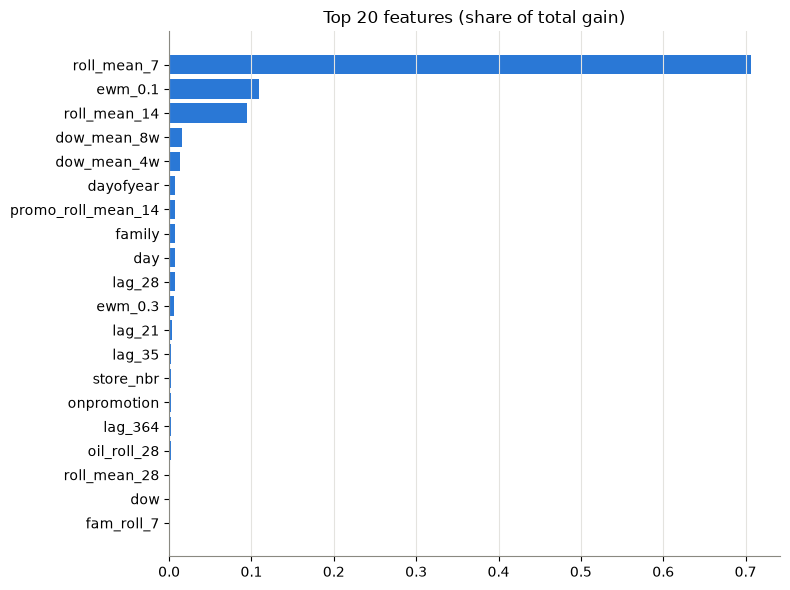

In [21]:
importance = pd.Series(global_model.feature_importance("gain"), index=FEATURES).sort_values().tail(20)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values / importance.sum(), color=BLUE)
ax.set_title("Top 20 features (share of total gain)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 5.8 Forecasts vs actuals

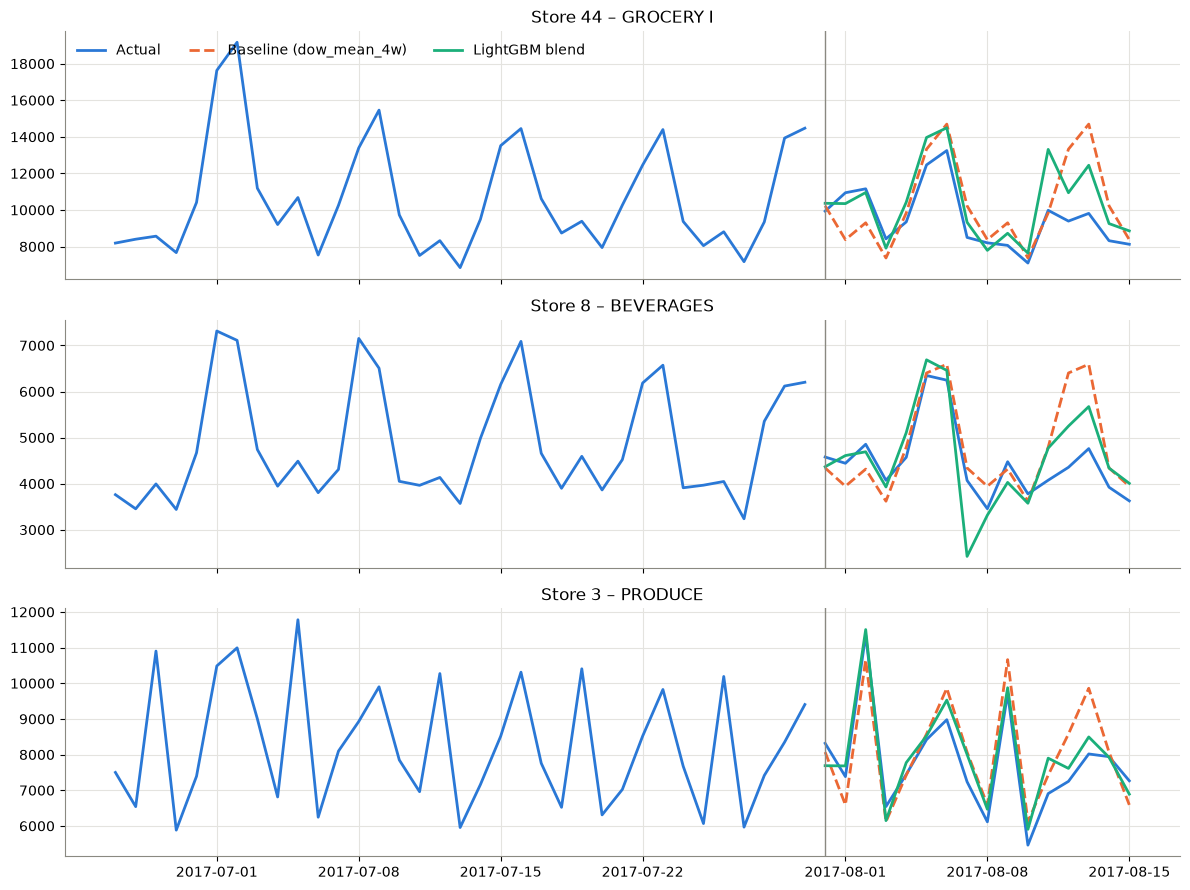

In [22]:
va_plot = va_part.assign(dow_mean_4w=valid_preds["dow_mean_4w"])
va_plot = va_plot.merge(val[["date", "store_nbr", "family"]].assign(
    blend=postprocess(val, p_blend), store_nbr=lambda d: d["store_nbr"].astype(int),
    family=lambda d: d["family"].astype(str)), on=["date", "store_nbr", "family"])

examples = [(44, "GROCERY I"), (8, "BEVERAGES"), (3, "PRODUCE")]
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 9), sharex=True)
for ax, (store, family) in zip(axes, examples):
    hist = tr_part[(tr_part["store_nbr"] == store) & (tr_part["family"] == family)].tail(35)
    s = va_plot[(va_plot["store_nbr"] == store) & (va_plot["family"] == family)]
    ax.plot(hist["date"], hist["sales"], color=BLUE, label="Actual")
    ax.plot(s["date"], s["sales"], color=BLUE)
    ax.plot(s["date"], s["dow_mean_4w"], color=ORANGE, linestyle="--", label="Baseline (dow_mean_4w)")
    ax.plot(s["date"], s["blend"], color=AQUA, label="LightGBM blend")
    ax.axvline(VALID_START, color="#8a8981", linewidth=1)
    ax.set_title(f"Store {store} – {family}")
axes[0].legend(frameon=False, ncols=3, loc="upper left")
plt.tight_layout()
plt.show()

## 6. Final fit and submissions
Retrain on all data with the median number of rounds from CV, then blend.

In [23]:
final_fit = full[(full["date"] >= TRAIN_FROM) & (full["date"] <= LAST_TRAIN) & ~earthquake]
test_rows = full[full["date"] > LAST_TRAIN]

global_rounds = int(np.median(cv_iters["global"]))
final_global = fit_lgb(final_fit, FEATURES, CATEGORICAL, GLOBAL_PARAMS, rounds=global_rounds)
p_global_test = final_global.predict(test_rows[FEATURES])

p_family_test = np.zeros(len(test_rows))
fit_groups = final_fit.groupby("family", observed=True)
for fam, tpart in test_rows.groupby("family", observed=True):
    rounds = max(1, int(np.median([iters[fam] for iters in cv_iters["per_family"]])))
    model = fit_lgb(fit_groups.get_group(fam), FAMILY_FEATURES, FAMILY_CATEGORICAL, FAMILY_PARAMS, rounds=rounds)
    p_family_test[test_rows.index.get_indexer(tpart.index)] = model.predict(tpart[FAMILY_FEATURES])
print(f"global rounds={global_rounds}")

global rounds=850


In [24]:
test_ids = test_rows["id"].astype(int).to_numpy()
subs = {
    "blend": pd.DataFrame({"id": test_ids, "sales": postprocess(test_rows, (p_global_test + p_family_test) / 2)}),
    "global": pd.DataFrame({"id": test_ids, "sales": postprocess(test_rows, p_global_test)}),
    "per_family": pd.DataFrame({"id": test_ids, "sales": postprocess(test_rows, p_family_test)}),
    "baseline_dow_mean_4w": pd.DataFrame({"id": test["id"], "sales": forecast_baseline(train, test, "dow_mean_4w")}),
}

sample = pd.read_csv(DATA / "sample_submission.csv")
for name, sub in subs.items():
    sub = sample[["id"]].merge(sub, on="id", how="left")
    assert len(sub) == len(sample) and sub["sales"].notna().all()
    sub.to_csv(OUT / f"submission_{name}.csv", index=False)
    print(f"wrote {OUT / f'submission_{name}.csv'}  rows={len(sub)}  mean sales={sub['sales'].mean():.1f}")

wrote submissions/submission_blend.csv  rows=28512  mean sales=439.3


wrote submissions/submission_global.csv  rows=28512  mean sales=440.4
wrote submissions/submission_per_family.csv  rows=28512  mean sales=439.9
wrote submissions/submission_baseline_dow_mean_4w.csv  rows=28512  mean sales=463.0
